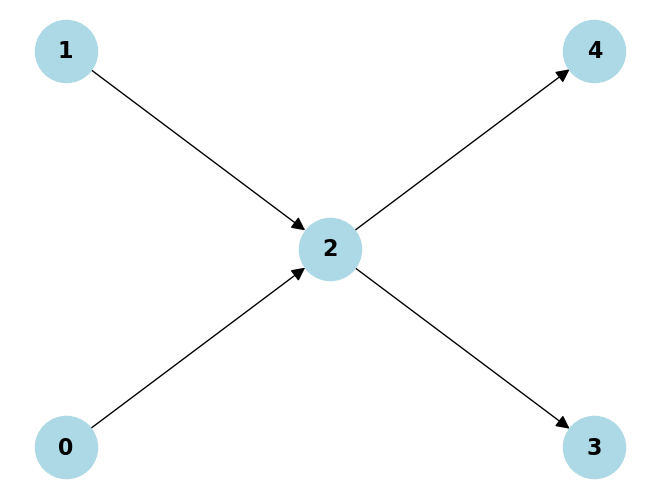

In [168]:
import networkx as nx

G = nx.DiGraph()
nodes = [0, 1, 2, 3, 4]
edges = [(0, 2), (1, 2), (2, 3), (2, 4)]
pos = {0: (0, 0), 1: (0, 2), 2: (1, 1), 3: (2, 0), 4: (2, 2)}
G.add_nodes_from(nodes)
G.add_edges_from(edges)
nx.draw(G, pos=pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=16, font_weight='bold', arrowsize=20)

In [222]:
import pandas as pd
import numpy as np
np.random.seed(120) 

k = 8
cols = ['edge', 'binom', 'total']
binom = [np.random.binomial(n=10, p=0.7) for _ in range(k*(len(edges)))]
total = [10 for _ in range(k*(len(edges)))]
k_series = pd.Series(np.repeat(range(k), len(edges)))

df = pd.DataFrame({'edge': k*edges,'binom': binom,'total': total, 'date': k_series})
df.head()

,edge,binom,total,date
0,"(0, 2)",6,10,0
1,"(1, 2)",7,10,0
2,"(2, 3)",7,10,0
3,"(2, 4)",7,10,0
4,"(0, 2)",7,10,1


In [223]:
df2 = df.copy()
df2['group_key'] = df2['edge'].apply(lambda x: f"{x[1]}")
df2 = df2.groupby(['group_key', 'date']).sum(numeric_only=True).reset_index()
df2.rename(columns={'group_key': 'node'}, inplace=True)
df2['node'] = df2['node'].astype(int)
df2['score'] = df2['binom'] / df2['total']
df2.head()

,node,date,binom,total,score
0,2,0,13,20,0.65
1,2,1,12,20,0.60
2,2,2,15,20,0.75
3,2,3,13,20,0.65
4,2,4,10,20,0.50


# Problem with Method of Moments, revisited

If there is a sample $[0.4, 0.4, 0.4]$, then the variance of that sample is $0$. This means that in the $\alpha = \bar{x}\left( \frac{\bar{x}(1-\bar{x})}{s^2}-1\right)$ we are dividing by zero. 

In [224]:
from scipy import stats
def mom(df):
    math_df = {}
    for edge in df['node'].unique():
        edge_df = df[df['node'] == edge]
        mean = edge_df['score'].mean()
        var = edge_df['score'].var()
        alpha = mean*((mean * (1 - mean)/var)-1)
        beta =  (1-mean)*((mean * (1 -mean)/var)-1)
        math_df[edge] = {'node': edge,'alpha': alpha, 'beta': beta}
    return pd.DataFrame.from_dict(math_df, orient='index')

math_df = mom(df2)
math_df['score2'] = stats.beta.cdf(0.7, math_df['alpha'], math_df['beta'])
math_df

,node,alpha,beta,score2
2,2,9.100000,3.900000,0.467478
3,3,7.875000,3.375000,0.464995
4,4,3.663021,1.972396,0.561117


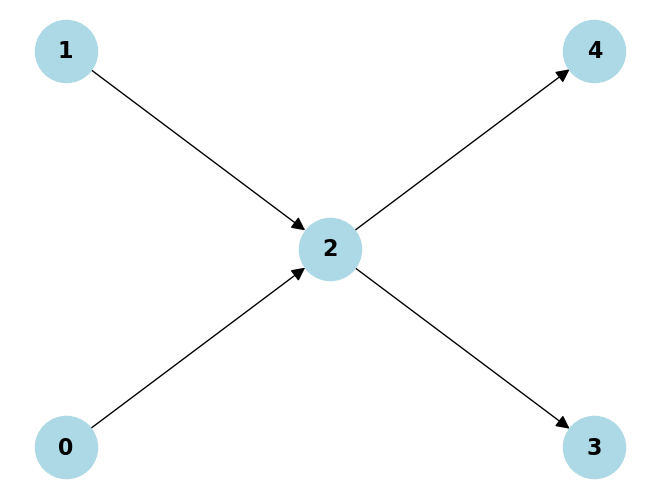

In [225]:
nx.draw(G, pos=pos, with_labels=True, node_color='lightblue', node_size=2000, font_size=16, font_weight='bold', arrowsize=20)
for node, data in G.nodes(data=True):
    if node in df2.index:
        data['score'] = df2[df2['node'] == node]['score'].mean()
    if node in math_df.index:
        data['score2'] = math_df.loc[node, 'score2']


In [276]:
from collections import defaultdict
score = nx.get_node_attributes(G, 'score')
score2 = nx.get_node_attributes(G, 'score2')

paths = {4: [[1,2,4], [0,2,4]], 3: [[1,2,3], [0,2,3]]}
score_dict = defaultdict(list)
score_dict2 = defaultdict(list)
for endpoint, path_list in paths.items():
    for path in path_list:
        path_score = 1
        path_score2 = 1
        for node in path:
            if node in score and not np.isnan(score[node]):
                path_score *= (1-score[node])
            if node in score2 and not np.isnan(score2[node]):
                path_score2 *= (1-score2[node])
            path_score = 1 - path_score
            path_score2 = 1 - path_score2
        score_dict[endpoint].append((round(path_score, 4)))
        score_dict2[endpoint].append((round(path_score2, 4)))
        print(f"Path: {path}, Score: {path_score:.4f}, Score2: {path_score2:.4f}")

Path: [1, 2, 4], Score: 0.6500, Score2: 0.5611
Path: [0, 2, 4], Score: 0.6500, Score2: 0.5611
Path: [1, 2, 3], Score: 0.7000, Score2: 0.4650
Path: [0, 2, 3], Score: 0.7000, Score2: 0.4650


In [284]:
# Endpoint Scores
score_dict3 = defaultdict(list)
score_dict4 = defaultdict(list)
for endpoint, paths in score_dict.items():
    endpoint_score = 1
    endpoint_score2 = 1
    for path_score in paths:
        endpoint_score *= (path_score)
        endpoint_score2 *= (1 - path_score)
    score_dict3[endpoint] = round(endpoint_score, 4)
    score_dict4[endpoint] = round(endpoint_score2, 4)
    print(f"Endpoint: {endpoint} Score: {score_dict3[endpoint]}, Score2: {score_dict4[endpoint]}")


Endpoint: 4 Score: 0.4225, Score2: 0.1225
Endpoint: 3 Score: 0.49, Score2: 0.09


In [287]:
prod = 1
prod2 = 1
for endpoint, score in score_dict3.items():
    prod *= (1-score)
    prod2 *= (1-score_dict4[endpoint])
prod = 1-prod
prod2 = 1-prod2
print(f"Product of Endpoint Scores: {prod:.4f}")
print(f"Product of Endpoint Scores2: {prod2:.4f}")

Product of Endpoint Scores: 0.7055
Product of Endpoint Scores2: 0.2015


In [ ]:
df_data = df.groupby('edge').sum().reset_index()[['edge', 'binom', 'total']]
df_data['alpha'] = df_data['binom'] + 1
df_data['beta'] = df_data['total']-df_data['binom'] + 1
df_data


,edge,binom,total,alpha,beta
0,"(0, 2)",59,80,60,22
1,"(1, 2)",53,80,54,28
2,"(2, 3)",56,80,57,25
3,"(2, 4)",52,80,53,29


In [ ]:
edge_map = df_data.set_index("edge")[["alpha", "beta"]].to_dict(orient="index")
for u, v, d in G.edges(data=True):
     match = edge_map.get((u, v))
     if match:
          d['params'] = (int(match['alpha']), int(match['beta']))

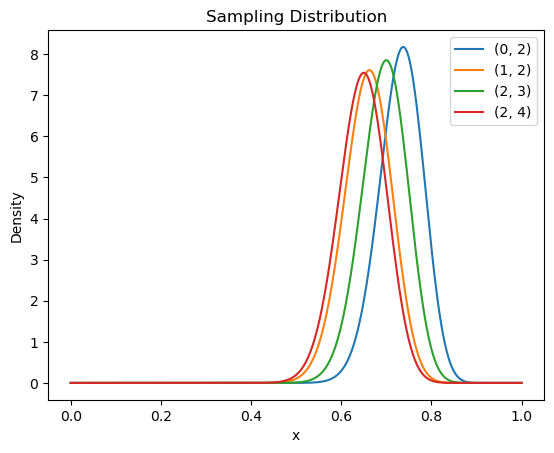

In [405]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats

# Define x values between 0 and 1
x = np.linspace(0, 1, 500)
for k, v in edge_map.items():
    y = stats.beta.pdf(x, *v.values())
    plt.plot(x, y, label=f"{k}")


# Plot the Beta distribution
plt.title("Sampling Distribution")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()

In [417]:
# Most expected probabilies
x = np.linspace(0, 1, 500)
for k, v in edge_map.items():
    y = stats.beta.pdf(x, *v.values())
    print(f'{k}, {x[np.argmax(y)]}')

(0, 2), 0.7374749498997996
(1, 2), 0.6633266533066132
(2, 3), 0.6993987975951903
(2, 4), 0.6492985971943888


In [412]:
for _  in range(5):
    for k, v in edge_map.items():
        print(f'{k}, {np.random.beta(*v.values()) > np.random.random()}')
    print()
        

(0, 2), True
(1, 2), True
(2, 3), True
(2, 4), True

(0, 2), True
(1, 2), False
(2, 3), True
(2, 4), False

(0, 2), True
(1, 2), True
(2, 3), False
(2, 4), False

(0, 2), True
(1, 2), True
(2, 3), True
(2, 4), False

(0, 2), True
(1, 2), True
(2, 3), False
(2, 4), True



In [452]:
import numpy as np
import networkx as nx
from tqdm import trange


def monte_carlo_connectivity(G,sources,targets,node_attr="score", edge_attr="params",n_sim=100_000,seed=None):

    rng = np.random.default_rng(seed)

    node_scores = nx.get_node_attributes(G, node_attr)
    edge_scores = nx.get_edge_attributes(G, edge_attr)

    counts = {target: 0 for target in targets}
    counts_any = 0
    counts_all = 0

    """ For the sake of demonstrating path dependance """
    paths = {4: [[1,2,4], [0,2,4]], 3: [[1,2,3], [0,2,3]]}
    path_results = {tuple(p): [] for path in paths.values() for p in path}
    
    for _ in trange(n_sim):

        if 0 == 1:
            # Sample node states
            active_nodes = []
            for node in G.nodes:
                p = node_scores.get(node, np.nan)
                if np.isnan(p):
                    active = True
                else:
                    active = rng.random() < p
                if active:
                    active_nodes.append(node)
        else:
            active_nodes = G.nodes()

        # Sample edge states
        active_edges = []
        for u, v in G.edges:
            params = edge_scores.get((u, v))
            if params is None:
                active = True
            else:
                a, b = params
                p = rng.beta(a, b)
                active = rng.random() < p
            if active:
                active_edges.append((u, v))

        # MC sample graph
        G_sample = G.edge_subgraph(active_edges)
        G_sample = G_sample.subgraph(active_nodes)


        # Find reachable nodes
        reachable = set()

        active_sources = set(sources) & set(G_sample.nodes)

        for source in active_sources:
            reachable.update(
                nx.descendants(G_sample, source)
            )
            reachable.add(source)

        # Endpoint results
        endpoint_reachable = {
            target: target in reachable
            for target in targets
        }
        for target, is_reachable in endpoint_reachable.items():
            if is_reachable:
                counts[target] += 1

        # Any endpoint is reachable
        if any(endpoint_reachable.values()):
            counts_any += 1

        # All endpoints are reachable
        if all(endpoint_reachable.values()):
            counts_all += 1

        """ Independence Test """
        for path in path_results:
            path_active = all(node in G_sample for node in path)
            path_results[path].append(path_active)
    
    return {'endpoint': {target: count / n_sim for target, count in counts.items()}, 'any': counts_any/n_sim, 'all': counts_all/n_sim}, path_results

In [453]:
results, path_res = monte_carlo_connectivity(G,sources=[0,1],targets=[3, 4],node_attr="score",edge_attr='params',n_sim=200,seed=123)
results2, path_res2 = monte_carlo_connectivity(G,sources=[2],targets=[3, 4],node_attr="score2",edge_attr='params',n_sim=200,seed=123)
print(f'Results: {results}, Results2: {results2}')

100%|██████████| 200/200 [00:00<00:00, 20846.44it/s]

Results: {'endpoint': {3: 0.645, 4: 0.625}, 'any': 0.835, 'all': 0.435}, Results2: {'endpoint': {3: 0.69, 4: 0.675}, 'any': 0.9, 'all': 0.465}


In [460]:
p1 = np.mean(path_res[(1, 2, 4)])
p2 = np.mean(path_res[(0, 2, 4)])
joint = np.mean(np.array(path_res[(1, 2, 4)])&np.array(path_res[(0, 2, 4)]))

print("P(P1):", p1)
print("P(P2):", p2)
print('Joint:', joint)
print("P1*P2:", p1*p2)
print("Gap from independence:", abs(joint - p1*p2))


P(P1): 0.42
P(P2): 0.495
Joint: 0.29
P1*P2: 0.2079
Gap from independence: 0.08209999999999998
